In [2]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from shapely.geometry import Point

Chargement du fichier des arbres et transformation de son systeme de coordonnees dans un syssteme de coordonnees projetees

In [3]:
arbres = gpd.read_file("data/les-arbres.geojson")
arbres.head()

,idbase,typeemplacement,domanialite,arrondissement,complementadresse,adresse,idemplacement,libellefrancais,genre,espece,varieteoucultivar,circonferenceencm,hauteurenm,stadedeveloppement,remarquable,geometry
0,288243,Arbre,Alignement,PARIS 12E ARRDT,54,BOULEVARD DIDEROT,001802003,Platane,Platanus,x hispanica,NaN,185,20,Adulte,NON,POINT (2.37978 48.84648)
1,2012138,Arbre,Jardin,BOIS DE VINCENNES,NaN,INSEP / AVENUE DU TREMBLAY,00040042,Robinier,Robinia,pseudoacacia,NaN,110,19,Adulte,NON,POINT (2.45595 48.8327)
2,2025524,Arbre,Alignement,PARIS 18E ARRDT,NaN,RUE ORDENER,000501004,Fevier,Gleditsia,triacanthos,''Sunburst'',30,4,Jeune (arbre),NON,POINT (2.35522 48.89045)
3,210947,Arbre,Alignement,PARIS 15E ARRDT,SN,RUE ERNEST HEMINGWAY,000202006,Charme-Houblon,Ostrya,carpinifolia,NaN,30,6,Jeune (arbre),NON,POINT (2.2746 48.83729)
4,216762,Arbre,Alignement,PARIS 7E ARRDT,NaN,PLACE DU PRESIDENT MITHOUARD,000203004,Paulownia,Paulownia,tomentosa,NaN,55,5,Jeune (arbre)Adulte,NON,POINT (2.31249 48.85063)


test des donnees pour verifier si tout est ok

In [4]:

print(arbres.shape)
print(arbres.columns)
arbres.info()
print(arbres.crs)

(220316, 16)
Index(['idbase', 'typeemplacement', 'domanialite', 'arrondissement',
       'complementadresse', 'adresse', 'idemplacement', 'libellefrancais',
       'genre', 'espece', 'varieteoucultivar', 'circonferenceencm',
       'hauteurenm', 'stadedeveloppement', 'remarquable', 'geometry'],
      dtype='str')
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 220316 entries, 0 to 220315
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype   
---  ------              --------------   -----   
 0   idbase              220316 non-null  int32   
 1   typeemplacement     220316 non-null  str     
 2   domanialite         220315 non-null  str     
 3   arrondissement      220316 non-null  str     
 4   complementadresse   78319 non-null   str     
 5   adresse             220316 non-null  str     
 6   idemplacement       220316 non-null  str     
 7   libellefrancais     216555 non-null  str     
 8   genre               220315 non-null  str     
 9   

Projection en lambert-93(EPSG:2154)

In [5]:
arbres = arbres.to_crs(epsg=2154)

print(arbres.crs)

EPSG:2154


Identification des arbres remarquable

In [6]:
arbre_remarquable = arbres[arbres['remarquable'] == 'OUI']

arbre_remarquable.head()

,idbase,typeemplacement,domanialite,arrondissement,complementadresse,adresse,idemplacement,libellefrancais,genre,espece,varieteoucultivar,circonferenceencm,hauteurenm,stadedeveloppement,remarquable,geometry
2815,135415,Arbre,Jardin,PARIS 17E ARRDT,17-12,SQUARE DES BATIGNOLLES / 144 RUE CARDINET,000204012,Plaqueminier,Diospyros,lotus,NaN,155,13,Adulte,OUI,POINT (649922.22 6865468.473)
4679,127516,Arbre,Jardin,PARIS 19E ARRDT,La rose des vents,SQUARE DE LA BUTTE DU CHAPEAU ROUGE / 11 BOULE...,000209001,Hêtre,Fagus,sylvatica,''Atropunicea'',286,19,Mature,OUI,POINT (655939.824 6864722.122)
5105,136304,Arbre,Jardin,PARIS 16E ARRDT,NaN,JARDIN DES SERRES D AUTEUIL / 1 AVENUE GORDON ...,000301009,Magnolia,Magnolia,grandiflora,NaN,195,10,Mature,OUI,POINT (645104.725 6861087.862)
5162,106714,Arbre,Jardin,PARIS 7E ARRDT,Canton 09,JARDIN DU CHAMP DE MARS ET PELOUSES DE L ECOLE...,P00905009,Plaqueminier,Diospyros,lotus,NaN,160,13,Adulte,OUI,POINT (648657.651 6861978.046)
6473,111331,Arbre,Jardin,PARIS 16E ARRDT,PELOUSE 20 - 75 à 77,JARDIN DE L AVENUE FOCH / 10 AVENUE FOCH,000307025,Platane,Platanus,x hispanica,NaN,450,27,Mature,OUI,POINT (647052.496 6863743.157)


Le plus haut arbre remarquable

In [7]:
hauteur_max_arbre_remarquable = arbre_remarquable['hauteurenm'].max()
print("Hauteur maximale :", hauteur_max_arbre_remarquable, "m")

Hauteur maximale : 45 m


Circonference maximum d'un arbre remarquable

In [8]:
circonference_max = arbre_remarquable["circonferenceencm"].max()

print("Circonférence maximale :", circonference_max, "cm")

Circonférence maximale : 740 cm


Filtre des arbres avec des tailles aberrantes

In [9]:
arbres[["hauteurenm", "circonferenceencm"]].describe()

,hauteurenm,circonferenceencm
count,220316.000000,220316.000000
mean,9.132551,83.836299
std,5.848270,63.094880
min,0.000000,0.000000
25%,5.000000,35.000000
50%,8.000000,75.000000
75%,13.000000,120.000000
max,112.000000,1198.000000


visualisation des valeurs aberantes avec boxplots

In [10]:
print("Maximum des hauteurs :", arbres["hauteurenm"].max())

print("Maximum des hauteurs d'arbre remarquable :",
      arbre_remarquable["hauteurenm"].max())

print("Minimum des hauteurs :", arbres["hauteurenm"].min())

Maximum des hauteurs : 112
Maximum des hauteurs d'arbre remarquable : 45
Minimum des hauteurs : 0


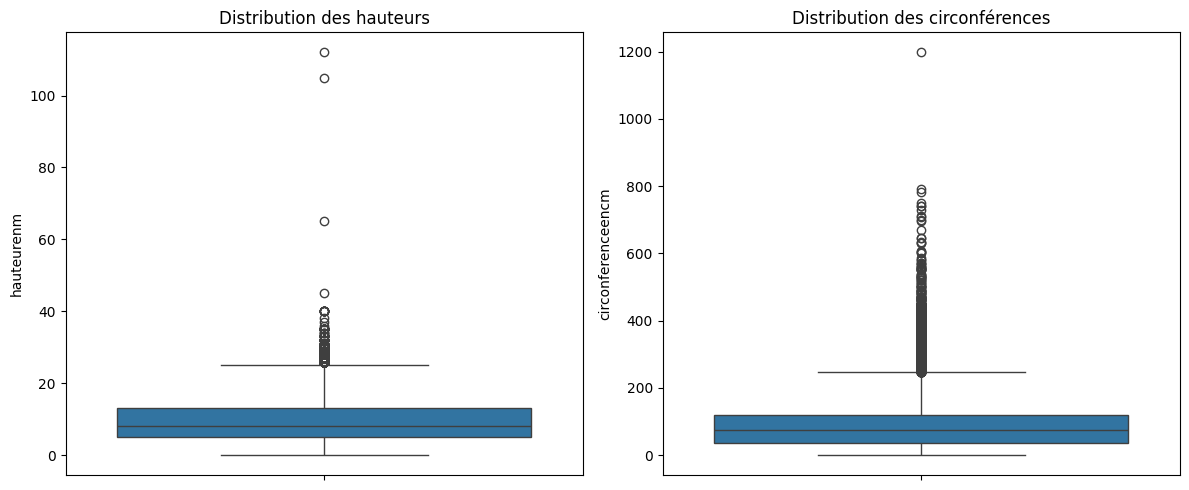

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=arbres["hauteurenm"], ax=axes[0])
axes[0].set_title("Distribution des hauteurs")

sns.boxplot(y=arbres["circonferenceencm"], ax=axes[1])
axes[1].set_title("Distribution des circonférences")

plt.tight_layout()
plt.show()

Filtrage des arbres pour qu'il n'y ait plus de valeur aberante

In [12]:
Q1_h = arbres["hauteurenm"].quantile(0.25)
Q3_h = arbres["hauteurenm"].quantile(0.75)

IQR_h = Q3_h - Q1_h

borne_min_h = Q1_h - 1.5 * IQR_h
borne_max_h = Q3_h + 1.5 * IQR_h


# Calcul des bornes pour les circonférences
Q1_c = arbres["circonferenceencm"].quantile(0.25)
Q3_c = arbres["circonferenceencm"].quantile(0.75)

IQR_c = Q3_c - Q1_c

borne_min_c = Q1_c - 1.5 * IQR_c
borne_max_c = Q3_c + 1.5 * IQR_c

arbres_filtres = arbres[
    (arbres["hauteurenm"] >= borne_min_h) &
    (arbres["hauteurenm"] <= borne_max_h) &
    (arbres["circonferenceencm"] >= borne_min_c) &
    (arbres["circonferenceencm"] <= borne_max_c)
].copy()

In [13]:
print("Nombre initial :", len(arbres))
print("Nombre après filtrage :", len(arbres_filtres))
print("Nombre supprimé :", len(arbres) - len(arbres_filtres))

Nombre initial : 220316
Nombre après filtrage : 215989
Nombre supprimé : 4327


Visualisation de la distribution des arbres en hauteur et en circonference

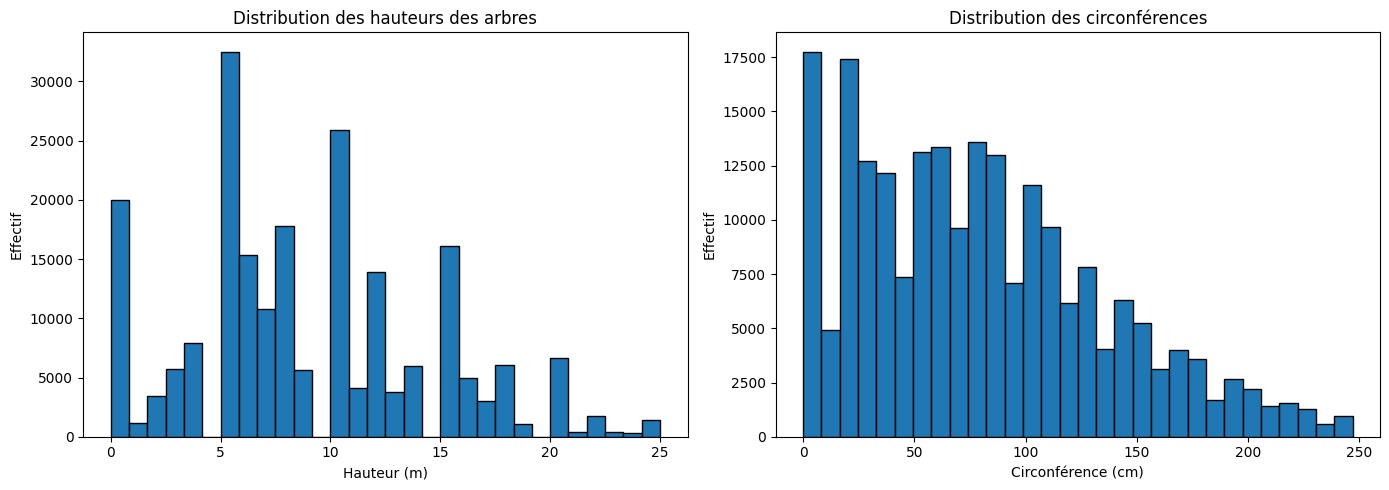

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme des hauteurs
axes[0].hist(
    arbres_filtres["hauteurenm"].dropna(),
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Distribution des hauteurs des arbres")
axes[0].set_xlabel("Hauteur (m)")
axes[0].set_ylabel("Effectif")

# Histogramme des circonférences
axes[1].hist(
    arbres_filtres["circonferenceencm"].dropna(),
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Distribution des circonférences")
axes[1].set_xlabel("Circonférence (cm)")
axes[1].set_ylabel("Effectif")

plt.tight_layout()
plt.show()

Tracage de la carte des hauteurs des arbres

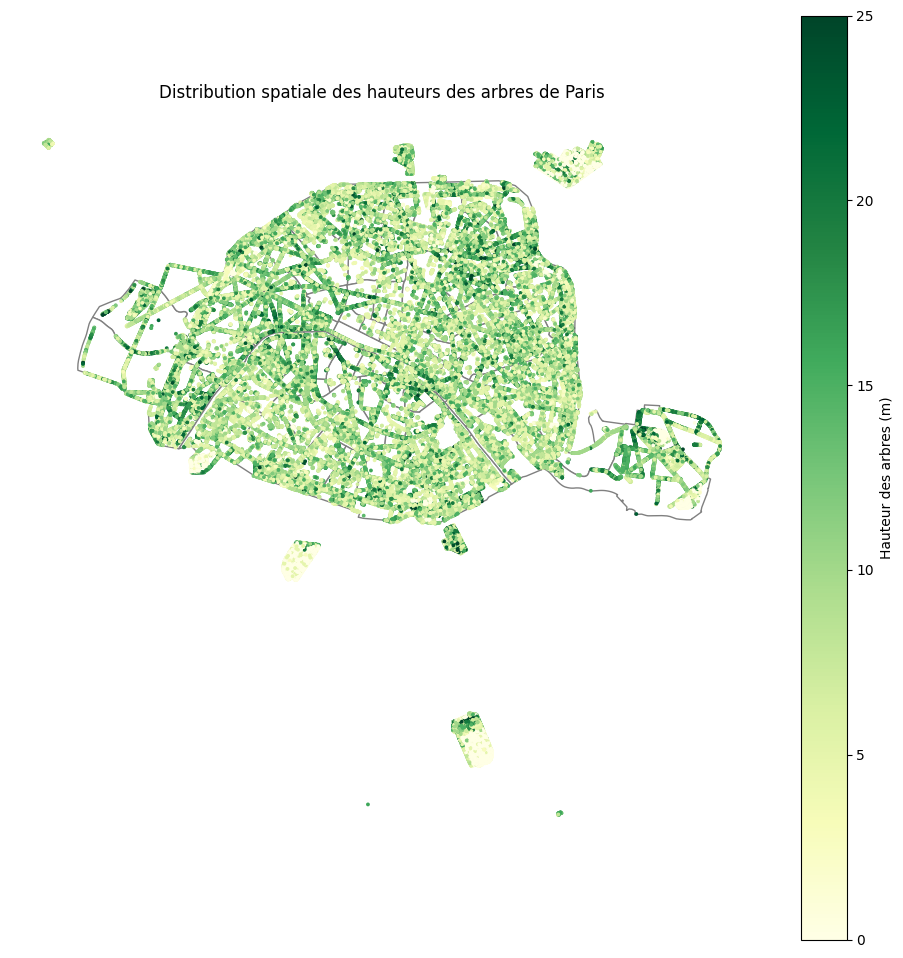

In [15]:
quartiers = gpd.read_file("data/quartier_paris.geojson")

quartiers = quartiers.to_crs(arbres_filtres.crs)

fig, ax = plt.subplots(figsize=(12, 12))

quartiers.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)


arbres_filtres.plot(
    ax=ax,
    column="hauteurenm",
    cmap="YlGn",
    markersize=3,
    legend=True,
    legend_kwds={"label": "Hauteur des arbres (m)"}
)

ax.set_title("Distribution spatiale des hauteurs des arbres de Paris")
ax.set_axis_off()

plt.show()

Comptage du nombre d'arbre de chaque genre

In [16]:
genres = arbres_filtres["libellefrancais"].value_counts()

print(genres.head(6))

libellefrancais
Platane       40283
Marronnier    23901
Tilleul       22967
Erable        20958
Sophora       10842
Chêne          5749
Name: count, dtype: int64


Affichage des 6 plus nombreux arbres

In [17]:
top6_genres = genres.head(6).index.tolist()

print(top6_genres)

['Platane', 'Marronnier', 'Tilleul', 'Erable', 'Sophora', 'Chêne']


visulaisation 

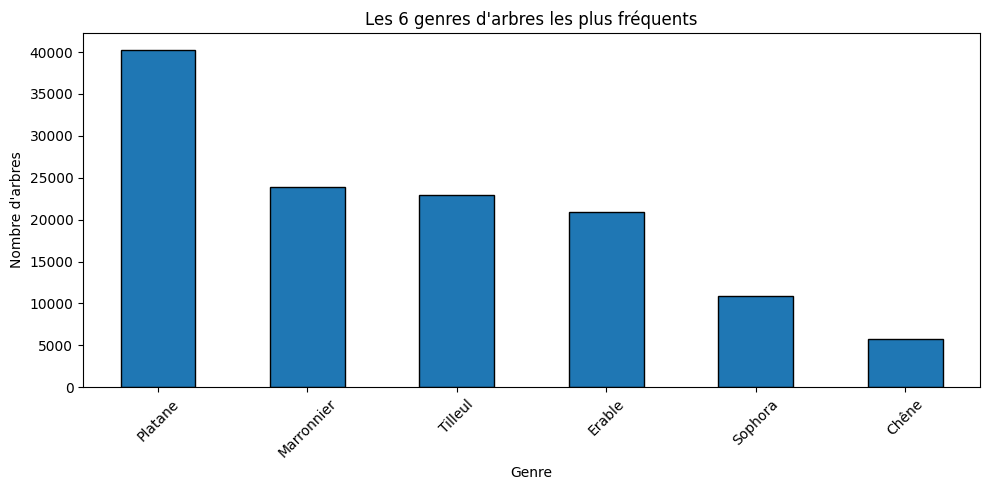

In [18]:
genres.head(6).plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.title("Les 6 genres d'arbres les plus fréquents")
plt.xlabel("Genre")
plt.ylabel("Nombre d'arbres")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

comparaison de la hauteur des 6 genres les plus frequents

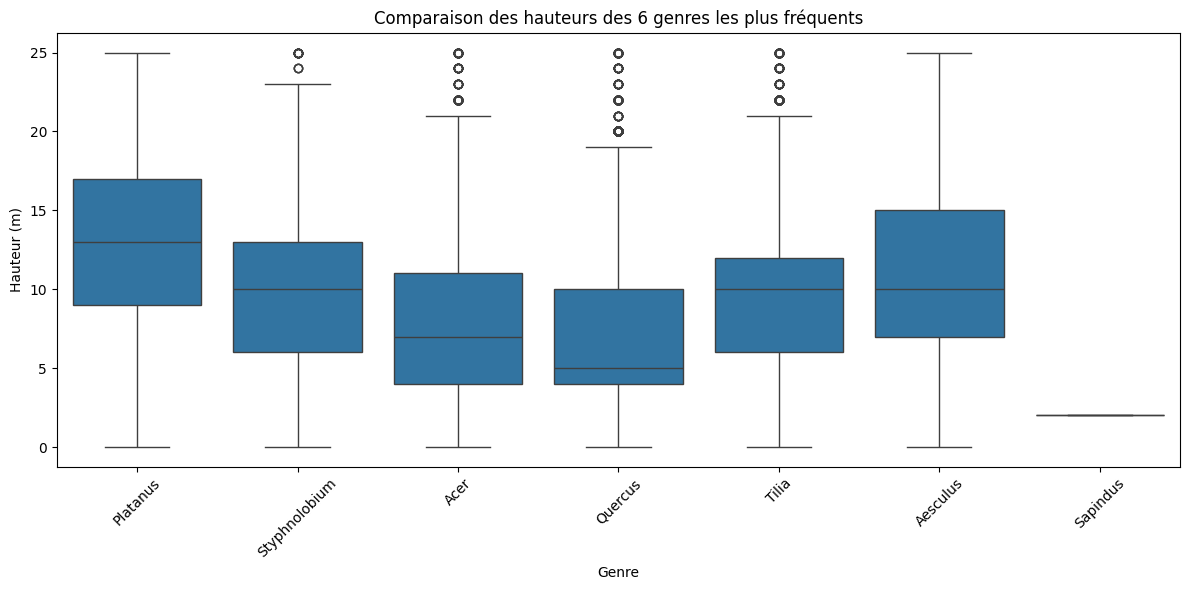

In [19]:

arbres_top6 = arbres_filtres[
    arbres_filtres["libellefrancais"].isin(top6_genres)
].copy()


arbres_top6 = arbres_top6.dropna(subset=["hauteurenm"])


plt.figure(figsize=(12, 6))

sns.boxplot(
    data=arbres_top6,
    x="genre",
    y="hauteurenm"
)

plt.title("Comparaison des hauteurs des 6 genres les plus fréquents")
plt.xlabel("Genre")
plt.ylabel("Hauteur (m)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [20]:
statistiques_genres = arbres_top6.groupby("libellefrancais")["hauteurenm"].agg(
    moyenne="mean",
    mediane="median"
)

print(statistiques_genres)

                   moyenne  mediane
libellefrancais                    
Chêne             7.096017      5.0
Erable            7.444937      7.0
Marronnier       10.950923     10.0
Platane          12.857930     13.0
Sophora           9.856207     10.0
Tilleul           9.467627     10.0


In [21]:
print(
    "Genre avec la moyenne la plus élevée :",
    statistiques_genres["moyenne"].idxmax()
)

Genre avec la moyenne la plus élevée : Platane


In [22]:
print(
    "Genre avec la mediane la plus élevée :",
    statistiques_genres["mediane"].idxmax()
)

Genre avec la mediane la plus élevée : Platane


In [23]:
def calcul_iqr(serie):
    return serie.quantile(0.75) - serie.quantile(0.25)


dispersion_genres = arbres_top6.groupby("libellefrancais")["hauteurenm"].agg(
    ecart_type="std",
    ecart_interquartile=calcul_iqr
)

print(dispersion_genres)

                 ecart_type  ecart_interquartile
libellefrancais                                 
Chêne              5.392897                  6.0
Erable             5.369791                  7.0
Marronnier         5.250596                  8.0
Platane            5.463243                  8.0
Sophora            4.561228                  7.0
Tilleul            4.892850                  6.0


In [24]:
print(
    "Genre avec le plus faible écart-type :",
    dispersion_genres["ecart_type"].idxmin()
)

Genre avec le plus faible écart-type : Sophora


In [25]:
print(
    "Genre avec le plus faible IQR :",
    dispersion_genres["ecart_interquartile"].idxmin()
)

Genre avec le plus faible IQR : Chêne


In [26]:
asymetrie_genres = arbres_top6.groupby("libellefrancais")["hauteurenm"].skew()

print(asymetrie_genres)

libellefrancais
Chêne         1.035937
Erable        0.406922
Marronnier    0.116908
Platane      -0.009354
Sophora       0.144266
Tilleul       0.011734
Name: hauteurenm, dtype: float64


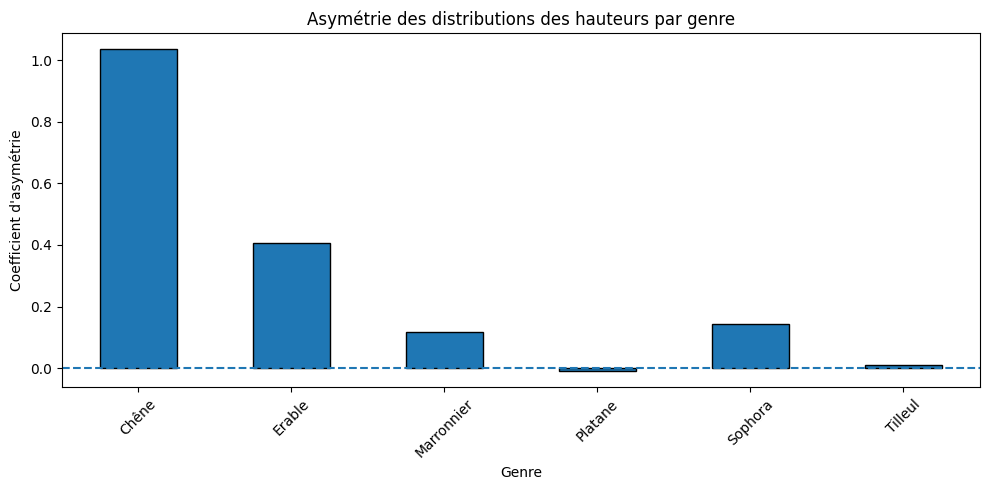

In [27]:
asymetrie_genres.plot(
    kind="bar",
    figsize=(10, 5),
    edgecolor="black"
)

plt.axhline(0, linestyle="--")

plt.title("Asymétrie des distributions des hauteurs par genre")
plt.xlabel("Genre")
plt.ylabel("Coefficient d'asymétrie")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Calcul du nombre d’arbres par quartier

In [28]:
jointure_spatiale = gpd.sjoin(arbres_filtres, quartiers, how="inner", predicate="within")

compte_arbres = jointure_spatiale.groupby("index_right").size()

quartiers["nb_arbres"] = quartiers.index.map(compte_arbres).fillna(0).astype(int)

print(quartiers[["l_qu", "nb_arbres"]].head())

                  l_qu  nb_arbres
0                Odéon        869
1             Roquette       1637
2  Faubourg-Montmartre        208
3             Vivienne        130
4             Archives        255


Calcul de la densité d’arbres par quartier

In [29]:
quartiers["surface_km2"] = quartiers.geometry.area / 1000000

quartiers["dens_arbres"] = quartiers["nb_arbres"] / quartiers["surface_km2"]

display(quartiers[["l_qu", "nb_arbres", "surface_km2", "dens_arbres"]].head())

,l_qu,nb_arbres,surface_km2,dens_arbres
0,Odéon,869,0.716148,1213.435734
1,Roquette,1637,1.172087,1396.654070
2,Faubourg-Montmartre,208,0.417335,498.400469
3,Vivienne,130,0.243551,533.769611
4,Archives,255,0.367728,693.446601


Comparaison des variables nombre et densité

In [30]:
moyenne_nb_arbres = quartiers["nb_arbres"].mean()
moyenne_densite_arbres = quartiers["dens_arbres"].mean()
ecartype_nb_arbres = quartiers["nb_arbres"].std()
ecartype_dens_arbres = quartiers["dens_arbres"].std()

print("Moyenne du nombre d'arbres par quartier :", moyenne_nb_arbres)
print("Moyenne de la densité d'arbres par quartier :", moyenne_densite_arbres)
print("Écart-type du nombre d'arbres par quartier :", ecartype_nb_arbres)
print("Écart-type de la densité d'arbres par quartier :", ecartype_dens_arbres)

Moyenne du nombre d'arbres par quartier : 2381.35
Moyenne de la densité d'arbres par quartier : 1630.2811072706147
Écart-type du nombre d'arbres par quartier : 2368.9041161246705
Écart-type de la densité d'arbres par quartier : 803.7006272836436


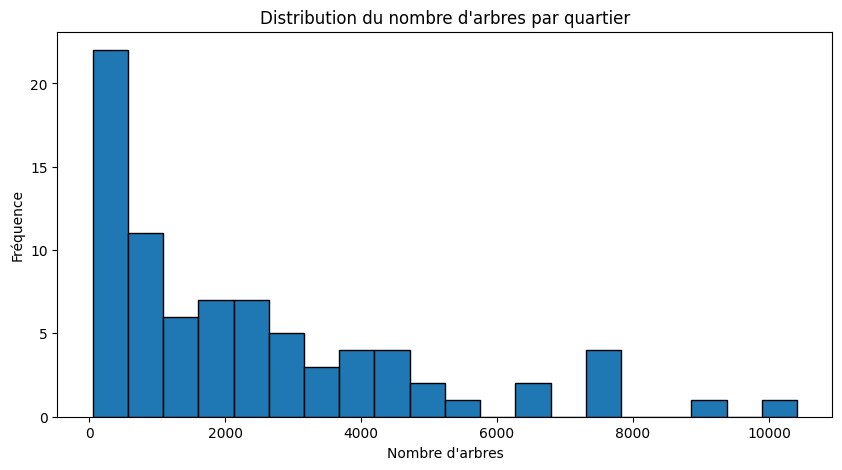

In [33]:
histo_nb_arbres = plt.figure(figsize=(10, 5))
plt.hist(
    quartiers["nb_arbres"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribution du nombre d'arbres par quartier")
plt.xlabel("Nombre d'arbres")
plt.ylabel("Fréquence")
plt.show()

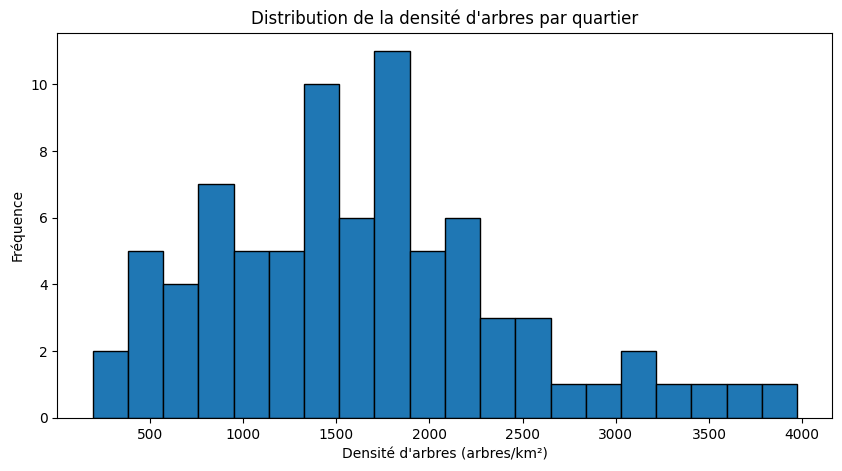

In [34]:
histo_dens_arbre = plt.figure(figsize=(10, 5))
plt.hist(
    quartiers["dens_arbres"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribution de la densité d'arbres par quartier")
plt.xlabel("Densité d'arbres (arbres/km²)") 
plt.ylabel("Fréquence")
plt.show()

calcule des indicateurs de formes (kurtosis et skewness) des distributions de ces deux variables


In [ ]:

for variable in ["hauteurenm", "circonferenceencm"]:
    serie = arbres_filtres[variable].dropna()

    asymetrie = serie.skew()           # skewness (asymétrie)
    kurtosis = serie.kurt()            # kurtosis (Fisher, normal = 0)

    print(f"Variable : {variable}")
    print(f"  Skewness (asymétrie) : {asymetrie:.3f}")
    print(f"  Kurtosis (Fisher)     : {kurtosis:.3f}")
    print("-" * 40)

Variable : hauteurenm
  Skewness (asymétrie) : 0.442
  Kurtosis (Fisher)     : -0.283
----------------------------------------
Variable : circonferenceencm
  Skewness (asymétrie) : 0.617
  Kurtosis (Fisher)     : -0.217
----------------------------------------
